# House Prices - Exploratory Data Analysis(EDA)

This notebook aims to perform an exploratory data analysis (EDA) on the Kaggle House Prices dataset.
The analysis is structured as follows:

1. Import libraries & Settings
2. Load data & basic information
3. Missing values analysis
4. Target variable distribution
5. Numerical features analysis
6. Categorical features analysis
7. Summary & insights

## 1. Import libraries & Settings
The environment is set up so plots and tables are consistently styled and readable.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.2)
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

## 2. Load data & basic information
The training and test datasets are loaded and their dimensions, column types and a first overview of the data are checked. 

This helps us understand the structure of the data and the detect potential issues early on.


In [3]:
train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")  
#readme里面说明请先下载train.csv/test.cvs放到data目录下

In [4]:
train_df.shape, test_df.shape

((1460, 81), (1459, 80))

In [5]:
train_df.dtypes

Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1         int64
BsmtFinType2      object
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating           object


In [6]:
display(train_df.head())
display(test_df.head())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,6,1998,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,20.0,TA,TA,PConc,TA,TA,No,GLQ,602.0,Unf,0.0,324.0,926.0,GasA,Ex,Y,SBrkr,926,678,0,1604,0.0,0.0,2,1,3,1,Gd,7,Typ,1,Gd,Attchd,1998.0,Fin,2.0,470.0,TA,TA,Y,360,36,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,Gtl,StoneBr,Norm,Norm,TwnhsE,1Story,8,5,1992,1992,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,263.0,Unf,0.0,1017.0,1280.0,GasA,Ex,Y,SBrkr,1280,0,0,1280,0.0,0.0,2,0,2,1,Gd,5,Typ,0,NaN,Attchd,1992.0,RFn,2.0,506.0,TA,TA,Y,0,82,0,0,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [7]:
train_df.info()
train_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 3. Missing Values Analysis
Many features in the House Price dataset contain missing values.

Here the proportion of missing data per column is calculated to identify which features require imputation or special handling.

In [8]:
na_rate = train_df.isna().mean().sort_values(ascending=False)
na_rate[na_rate > 0].head(20)

PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageYrBlt     0.055479
GarageCond      0.055479
GarageType      0.055479
GarageFinish    0.055479
GarageQual      0.055479
BsmtFinType2    0.026027
BsmtExposure    0.026027
BsmtQual        0.025342
BsmtCond        0.025342
BsmtFinType1    0.025342
MasVnrArea      0.005479
Electrical      0.000685
dtype: float64

In [26]:
def fill_na_default(dataset):
    na_rate = dataset.isna().mean().sort_values(ascending = False)
    na_cols = na_rate[na_rate>0].index
    for na_col in na_cols:
        if dataset[na_col].dtype == 'object':
            dataset[na_col].fillna('None', inplace = True)
        else:
            dataset[na_col].fillna(dataset[na_col].median(), inplace = True)
        
    return dataset

def fill_na_special(dataset):
    dataset = fill_na_default(dataset)
    
    dataset["PoolQC"].fillna("None", inplace=True)
    dataset["GarageYrBlt"].fillna(0, inplace=True)
    dataset["MasVnrArea"].fillna(0, inplace=True)
    dataset["LotFrontage"] = dataset.groupby("Neighborhood")["LotFrontage"].transform(
        lambda x: x.fillna(x.median())
    )

    return dataset

fill_na_special(train_df);
fill_na_special(test_df);

/var/folders/mx/3xbwl6hn4m1fhs1591dm_nz80000gn/T/ipykernel_31807/2895612406.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset["PoolQC"].fillna("None", inplace=True)
/var/folders/mx/3xbwl6hn4m1fhs1591dm_nz80000gn/T/ipykernel_31807/2895612406.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values alwa

In [10]:
#after filling missing values
print(train_df.isna().sum().sum())
print("*"*50)
print(test_df.isna().sum().sum())

0
**************************************************
0


## 4. Target Variable Distribution
The target variable 'SalePrice' is typically right-skewed.

Its distribution is examined and a log transformation is applied to make it closer to a normal distribution, which often improves model performance.

1.8828757597682129


<Axes: xlabel='SalePrice', ylabel='Count'>

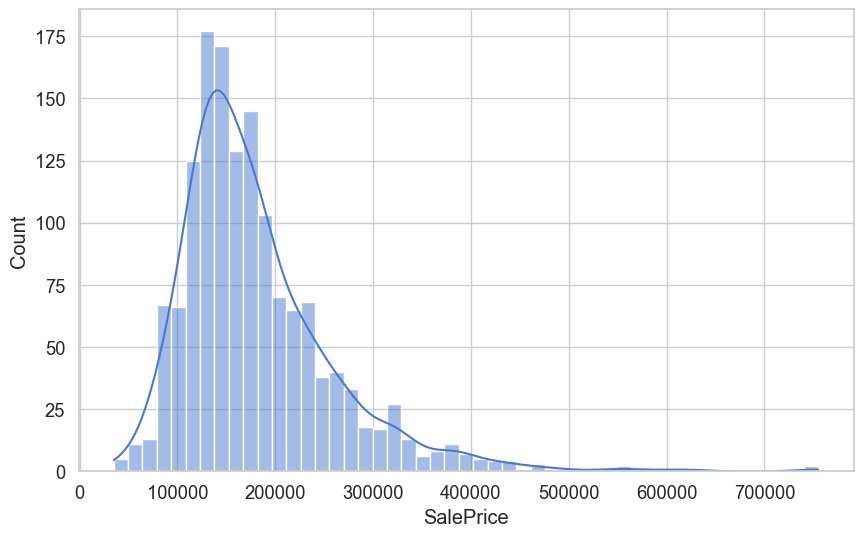

In [11]:
print(train_df['SalePrice'].skew())
sns.histplot(train_df['SalePrice'], kde= True)

0.12134661989685329


<Axes: xlabel='SalePrice_Log1p', ylabel='Count'>

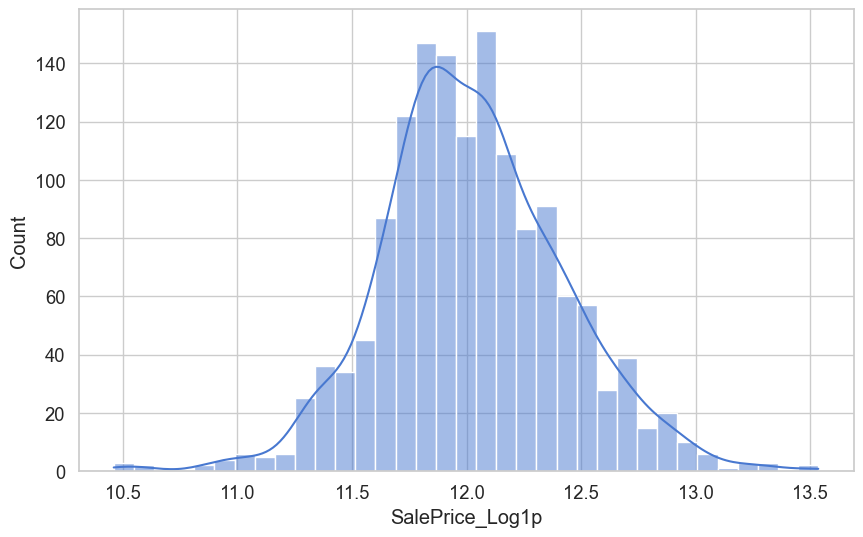

In [12]:
train_df['SalePrice_Log1p'] = np.log1p(train_df['SalePrice'])
print(train_df['SalePrice_Log1p'].skew())

sns.histplot(train_df['SalePrice_Log1p'], kde= True)

## 5. Numerical Features Analysis
The numerical features are explored to understand their distribution and relationships with the target variable.

In [13]:
#have a view of the numerical and categorical columns
num_cols = train_df.select_dtypes(include = [np.number]).columns.tolist()
cat_cols = train_df.select_dtypes(include = ['object']).columns.tolist()
print(num_cols)
print("*"*50)
print(cat_cols)

['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice', 'SalePrice_Log1p']
**************************************************
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQ

In [14]:
df = train_df.copy()

target = 'SalePrice_Log1p'


continuous_num_features = [
    "LotFrontage","LotArea","MasVnrArea",
    "BsmtFinSF1","BsmtFinSF2","BsmtUnfSF","TotalBsmtSF",
    "1stFlrSF","2ndFlrSF","LowQualFinSF","GrLivArea","GarageArea",
    "WoodDeckSF","OpenPorchSF","EnclosedPorch","3SsnPorch","ScreenPorch","PoolArea"
]

discrete_num_features = [
    "GarageCars","BedroomAbvGr","KitchenAbvGr","TotRmsAbvGrd",
    "FullBath","HalfBath","BsmtFullBath","BsmtHalfBath","Fireplaces"
]

temporal_num_features = ["YearBuilt","YearRemodAdd","YrSold","MoSold","GarageYrBlt"]

cat_features = [
    "MSSubClass","MSZoning","Street","Alley","LotShape","LandContour",
    "Utilities","LotConfig","LandSlope","Neighborhood","Condition1","Condition2",
    "BldgType","HouseStyle","RoofStyle","RoofMatl","Exterior1st","Exterior2nd",
    "MasVnrType","Foundation","Heating","CentralAir","Electrical",
    "GarageType","GarageFinish","PavedDrive","Fence","MiscFeature",
    "SaleType","SaleCondition"
]

ordinal_cat_features = [
    "OverallQual","OverallCond",
    "ExterQual","ExterCond",
    "BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2",
    "HeatingQC","KitchenQual","FireplaceQu",
    "GarageQual","GarageCond",
    "PoolQC","Functional"
]

special = ["MiscVal"]

all_features = continuous_num_features+discrete_num_features+temporal_num_features+cat_features+ordinal_cat_features+special
missing = set(train_df.columns) - set(all_features) - {"SalePrice", "SalePrice_Log1p"}
print("not grouped features:", missing)

not grouped features: {'Id'}


In [15]:
if {"YearBuilt","YrSold"}.issubset(df.columns):
    df['HouseAge'] = df['YrSold']-df['YearBuilt']
if {"YrSold", "YearRemodAdd"}.issubset(df.columns):
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
if {'YrSold','GarageYrBilt'}.issubset(df.columns):
    df['GarageAge'] = df['YrSold'] - df['GarageYrBlt']

engineered_temporal = [c for c in ['HouseAge', 'RemodAge','GarageAge'] if c in df.columns]

In [ ]:
num_for_corr = [c for c in continuous_num_features + discrete_num_features + engineered_temporal if c in df.columns]
num_df = df[num_for_corr + [target]].replace([np.inf, -np.inf], np.nan)

valid = [c for c in num_df.columns if num_df[c].notna().sum() >= 3 and num_df[c].nunique(dropna = True) >1]
num_df = num_df[valid]

corr_p = num_df.corr()[target].abs().drop(index = target, errors = 'ignore').sort_values(ascending = False)
corr_s = num_df.corr(method = 'spearman')[target].abs().drop(index = target, errors = 'ignore').sort_values(ascending = False)

corr_score = pd.concat([corr_p.rename('pearson'), corr_s.rename('spearman')], axis = 1).fillna(0)
corr_score['score'] = corr_score.max(axis = 1)
corr_score = corr_score.sort_values('score', ascending = False)

top_num = corr_score.head(10).index.tolist()
weak_num = corr_score[corr_score['score']<0.1].index.tolist()

print("high relevance features:\n ", top_num)
print("low relebance features: \n", weak_num)


high relevance features:
  ['GrLivArea', 'GarageCars', 'GarageArea', 'HouseAge', 'FullBath', 'TotalBsmtSF', '1stFlrSF', 'RemodAge', 'TotRmsAbvGrd', 'Fireplaces']
low relebance features: 
 ['PoolArea', 'LowQualFinSF', '3SsnPorch', 'BsmtFinSF2', 'BsmtHalfBath']


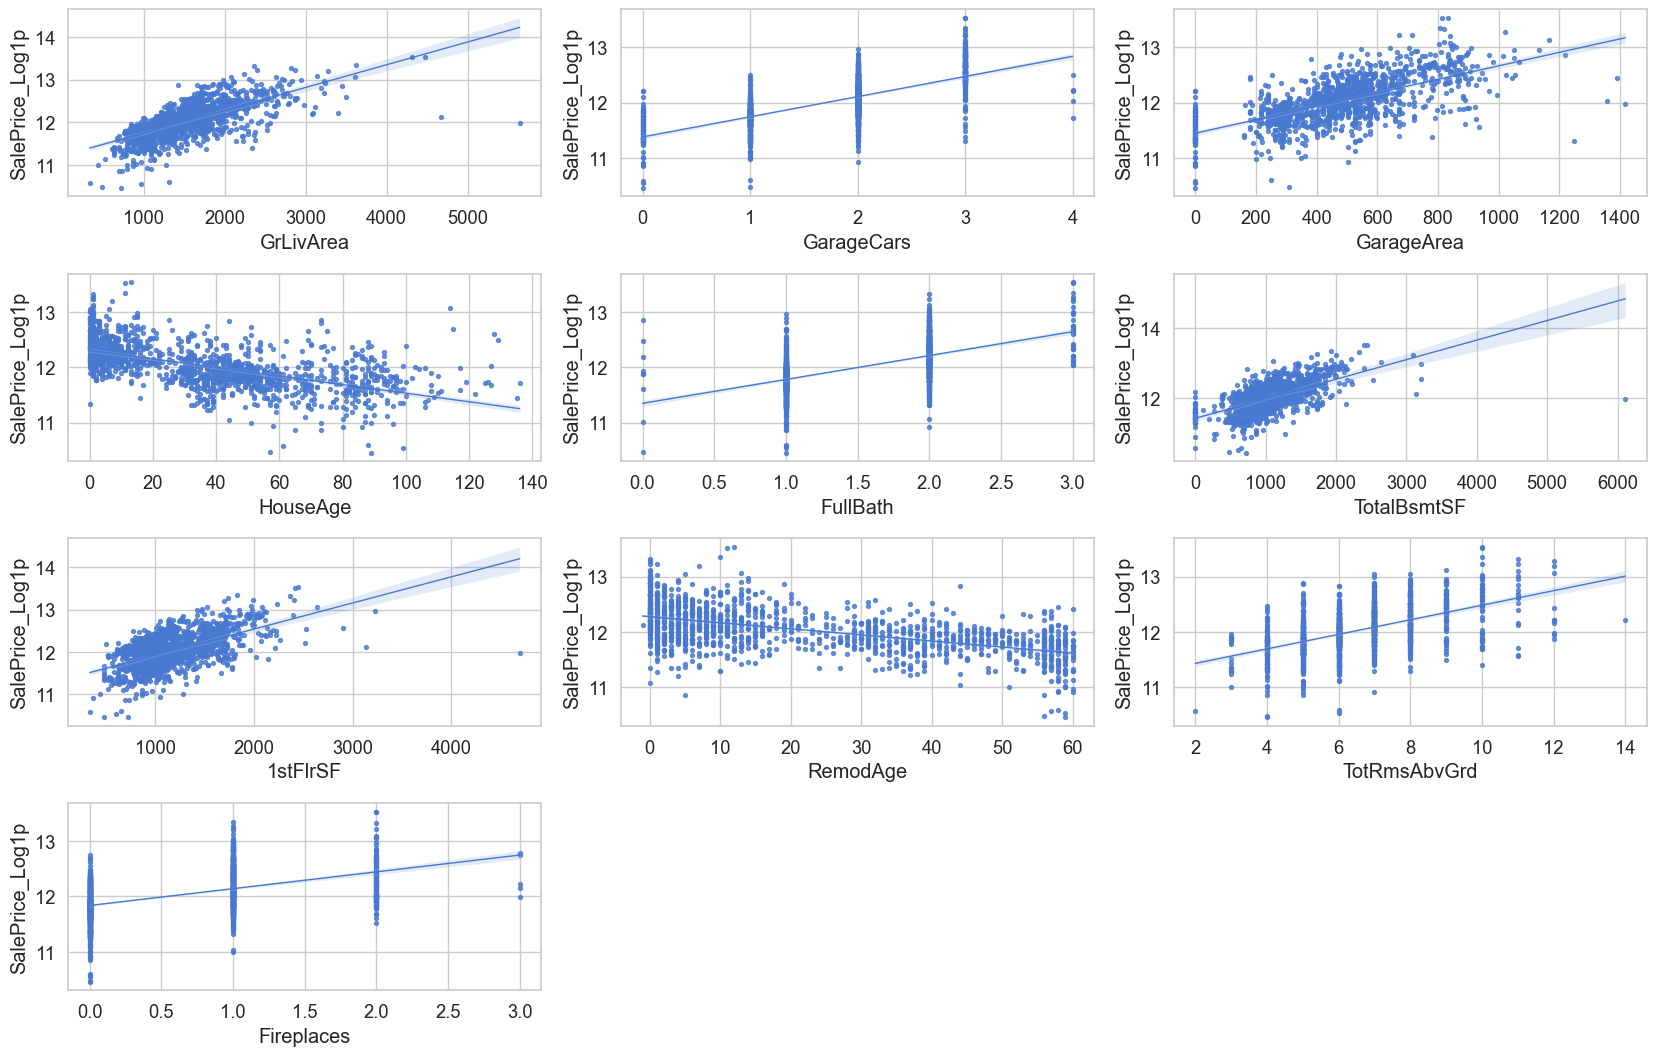

In [17]:
n = len(top_num)
n_cols = 3
n_rows = (n+n_cols-1)//n_cols
fig,axs = plt.subplots(n_rows, n_cols,figsize = (n_rows*4.2, n_cols*3.6))
axs = np.atleast_2d(axs)

for i, col in enumerate(top_num):
    r,c = divmod(i, n_cols)
    s = df[[col,target]].dropna()
    ax = axs[r][c]
    sns.regplot(x = s[col], y = s[target], ax = ax, scatter_kws = {'s':8}, line_kws = {'linewidth':1})

for j in range(n, n_rows*n_cols):
    fig.delaxes(axs[j//n_cols, j%n_cols])

plt.tight_layout();
plt.show()

## 6. Categorical Features Analysis

Categorical features, their frequencies, and their effect on the target variable are analyzed.

In [18]:
map_qual = {"Po":1,"Fa":2,"TA":3,"Gd":4,"Ex":5}
map_expo = {"No":1,"Mn":2,"Av":3,"Gd":4}
map_fin  = {"Unf":1,"LwQ":2,"Rec":3,"BLQ":4,"ALQ":5,"GLQ":6}
map_func = {"Sev":1,"Maj2":2,"Maj1":3,"Mod":4,"Min2":5,"Min1":6,"Typ":7}

col2map = {
    "ExterQual": map_qual, "ExterCond": map_qual,
    "BsmtQual": map_qual, "BsmtCond": map_qual,
    "BsmtExposure": map_expo,
    "BsmtFinType1": map_fin, "BsmtFinType2": map_fin,
    "HeatingQC": map_qual, "KitchenQual": map_qual, "FireplaceQu": map_qual,
    "GarageQual": map_qual, "GarageCond": map_qual,
    "Functional": map_func
}

In [19]:
ord_cat_cols = []

for col in ordinal_cat_features:
    if col not in df.columns:
        continue
    if col in ['OverallQual', 'OverallCond']:
        df[col+'_ord'] = df[col]
    else:
        df[col+'_ord'] = df[col].map(col2map.get(col, {}))
    ord_cat_cols.append(col + '_ord')

ord_cat_corr = df[ord_cat_cols+[target]].corr(method = 'spearman')[target].abs().drop(target, errors = 'ignore').sort_values(ascending = False)

print("ordinal categorical correlance:",ord_cat_corr.head(10))

ordinal categorical correlance: OverallQual_ord     0.809829
ExterQual_ord       0.684014
KitchenQual_ord     0.672849
BsmtQual_ord        0.664393
HeatingQC_ord       0.491392
BsmtFinType1_ord    0.325257
BsmtExposure_ord    0.304819
FireplaceQu_ord     0.241431
GarageQual_ord      0.197412
BsmtCond_ord        0.196402
Name: SalePrice_Log1p, dtype: float64


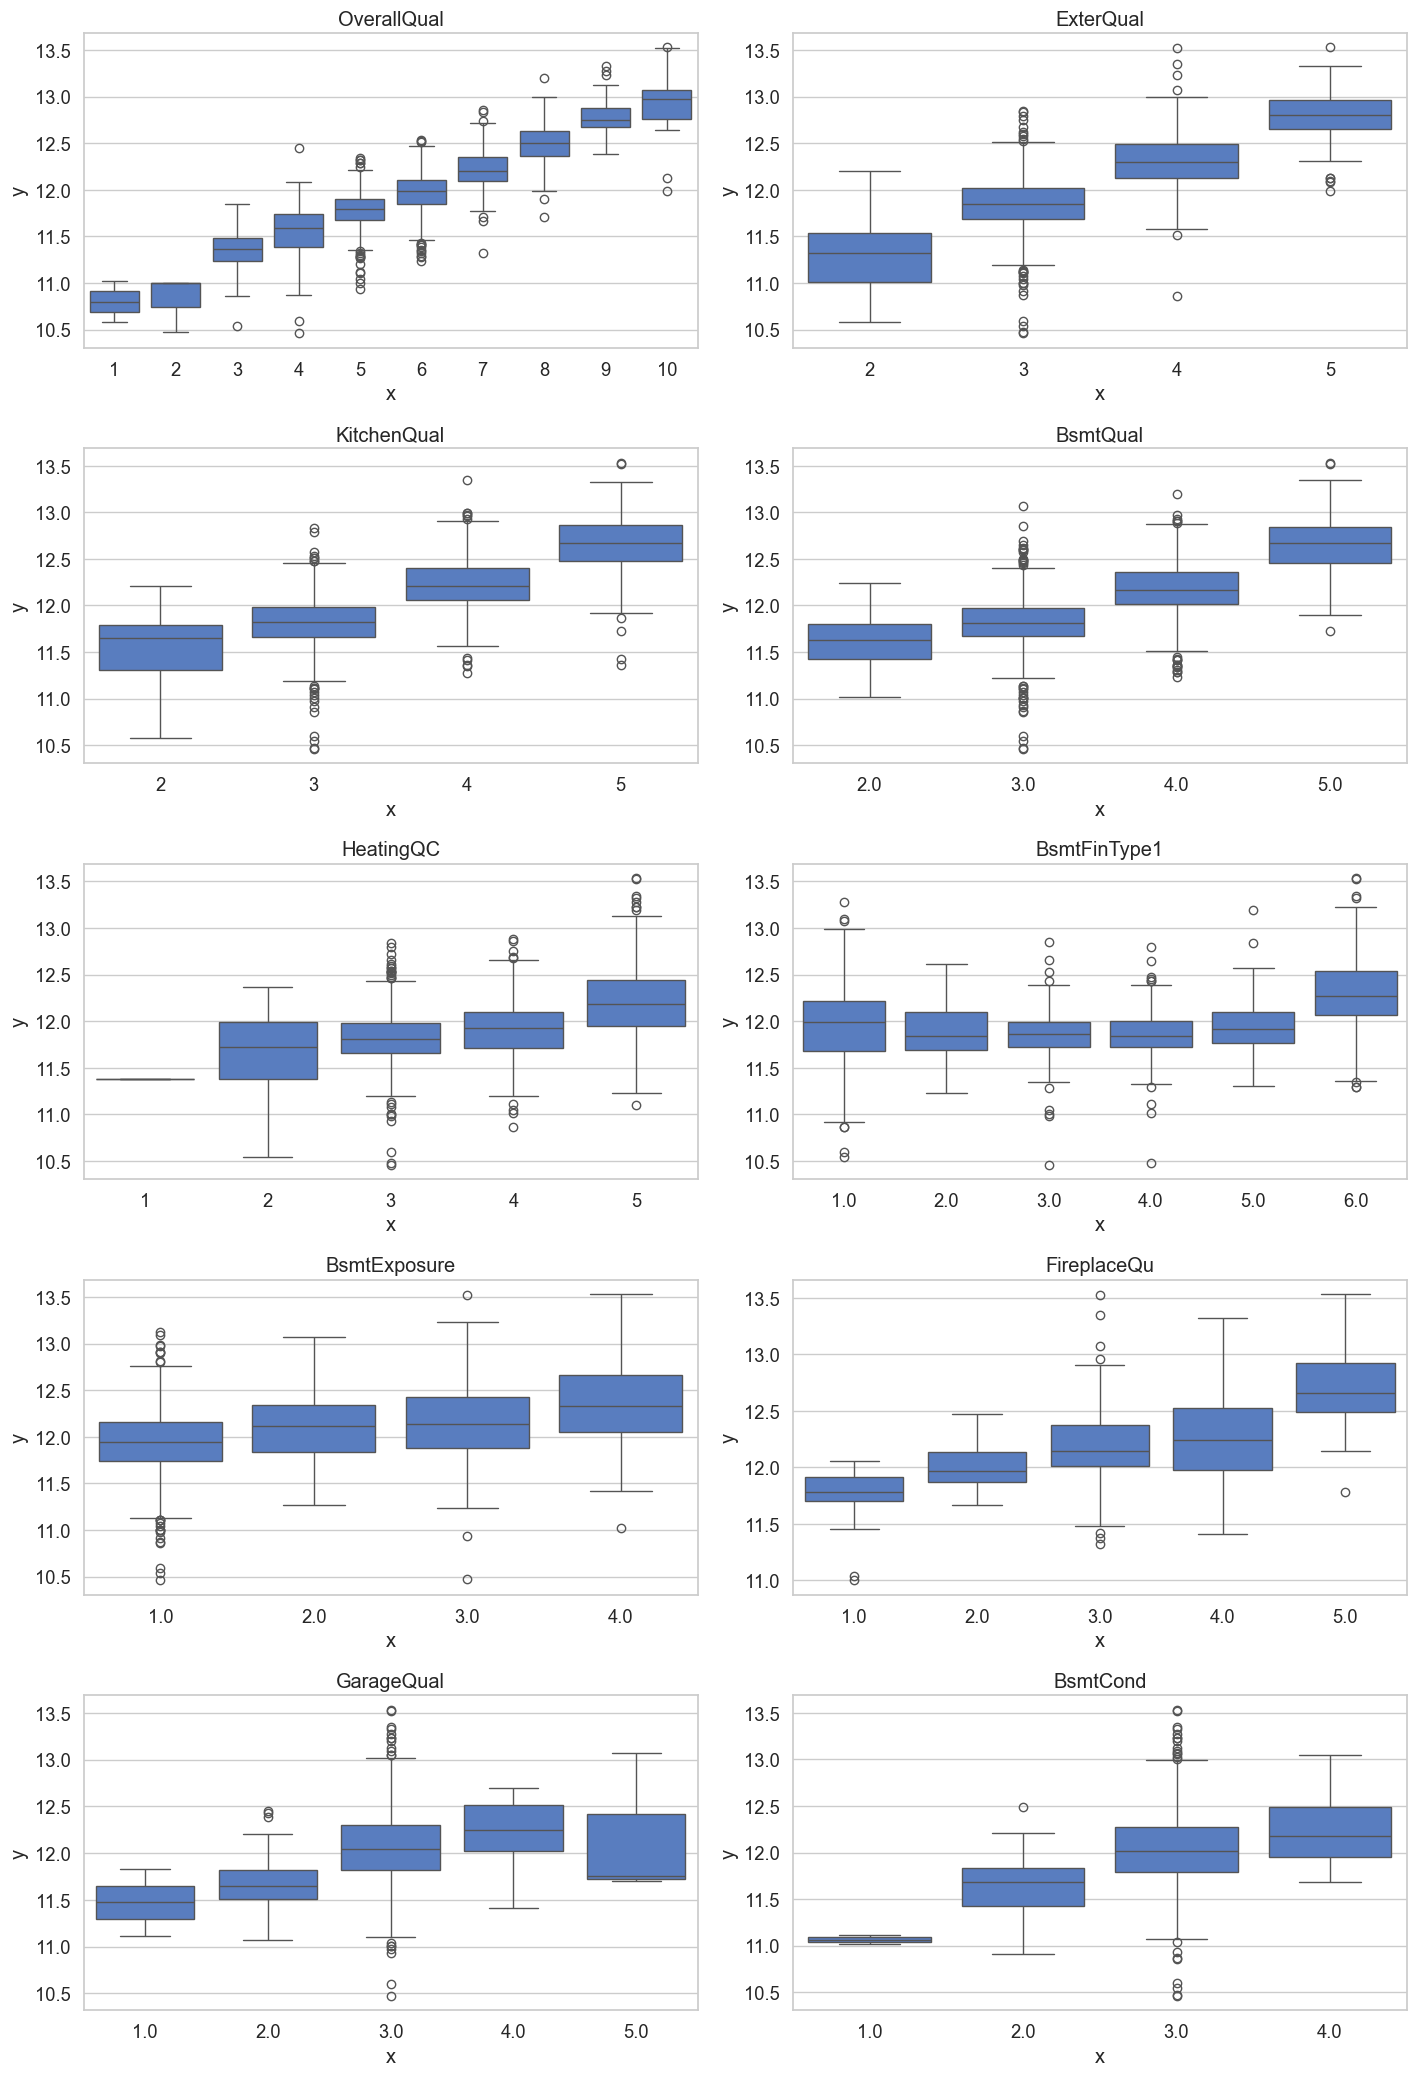

In [20]:
items = list(ord_cat_corr.head(10).index) 
n = len(items)
n_cols = 2
n_rows = (n + n_cols - 1) // n_cols

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 7.2, n_rows * 4.2))
axs = np.atleast_2d(axs)


y_vals = df[target]

for i, col_ord in enumerate(items):
    r, c = divmod(i, n_cols)
    ax = axs[r][c]

    s = pd.DataFrame({"x": df[col_ord], "y": y_vals}).dropna()
    if s.empty:
        ax.set_visible(False)
        continue

    sns.boxplot(x=s["x"].astype("category"), y=s["y"], ax=ax)
    ax.set_title(col_ord.replace("_ord", ""))


for j in range(n, n_rows * n_cols):
    fig.delaxes(axs[j // n_cols, j % n_cols])

plt.tight_layout()
plt.show()


In [21]:
def pick_cats_by_mean_gap(df, cat_cols, target, min_count = 20, top_feats = 5):
    gaps = {}
    for col in cat_cols:
        if col not in df.columns:
            continue
        gap = df.groupby(col)[target].agg(['mean','count']).query('count>= @min_count')
        if len(gap) >=2:
            gaps[col] = gap['mean'].max() - gap['mean'].min()
    return sorted(gaps, key = gaps.get, reverse = True)[:top_feats]

best_cats = pick_cats_by_mean_gap(df, cat_features, target, min_count = 20, top_feats = 5)
print('top gap cats:' , best_cats)

top gap cats: ['Neighborhood', 'MSSubClass', 'GarageType', 'GarageFinish', 'Foundation']


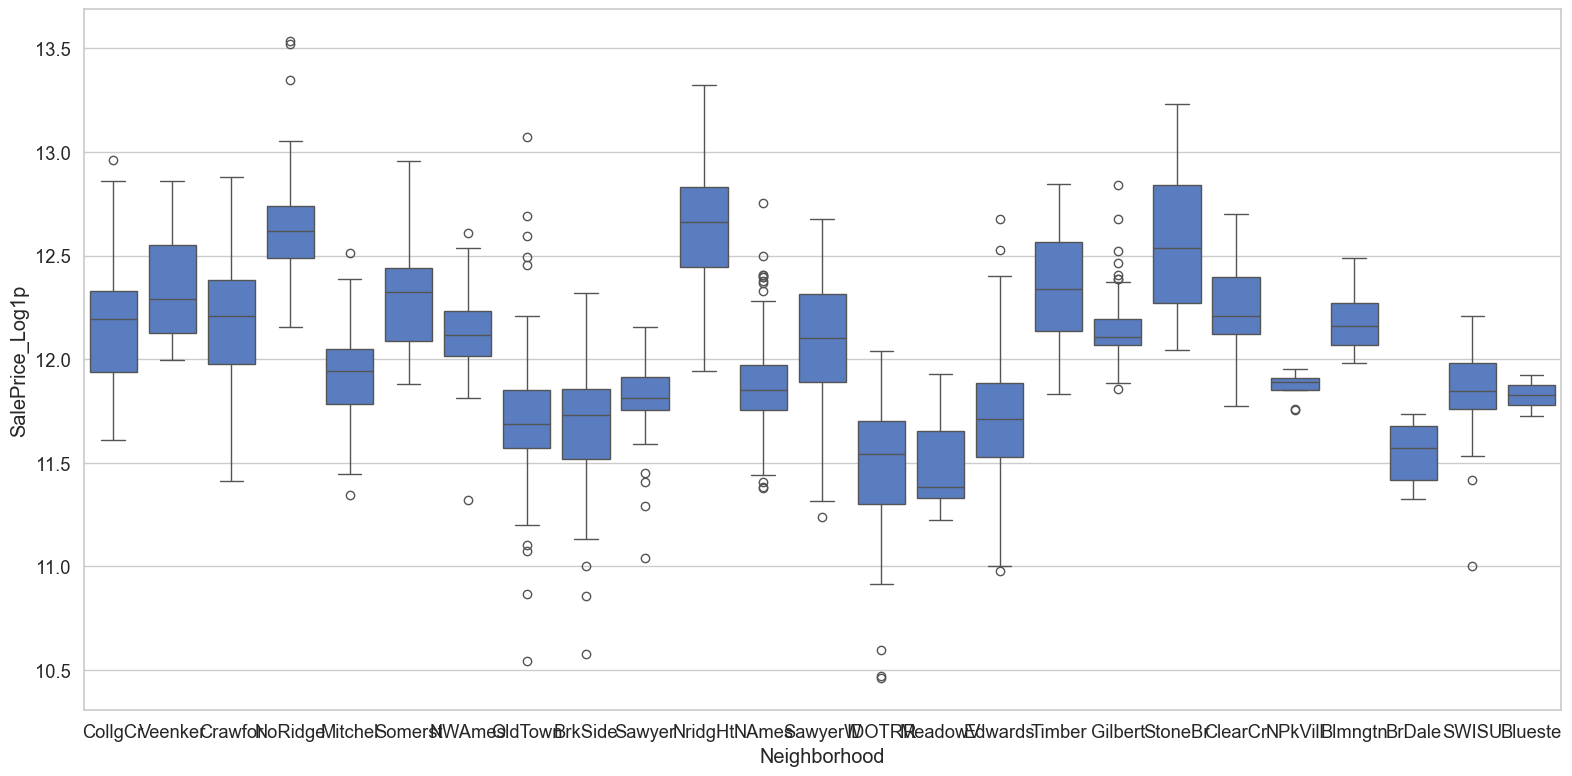

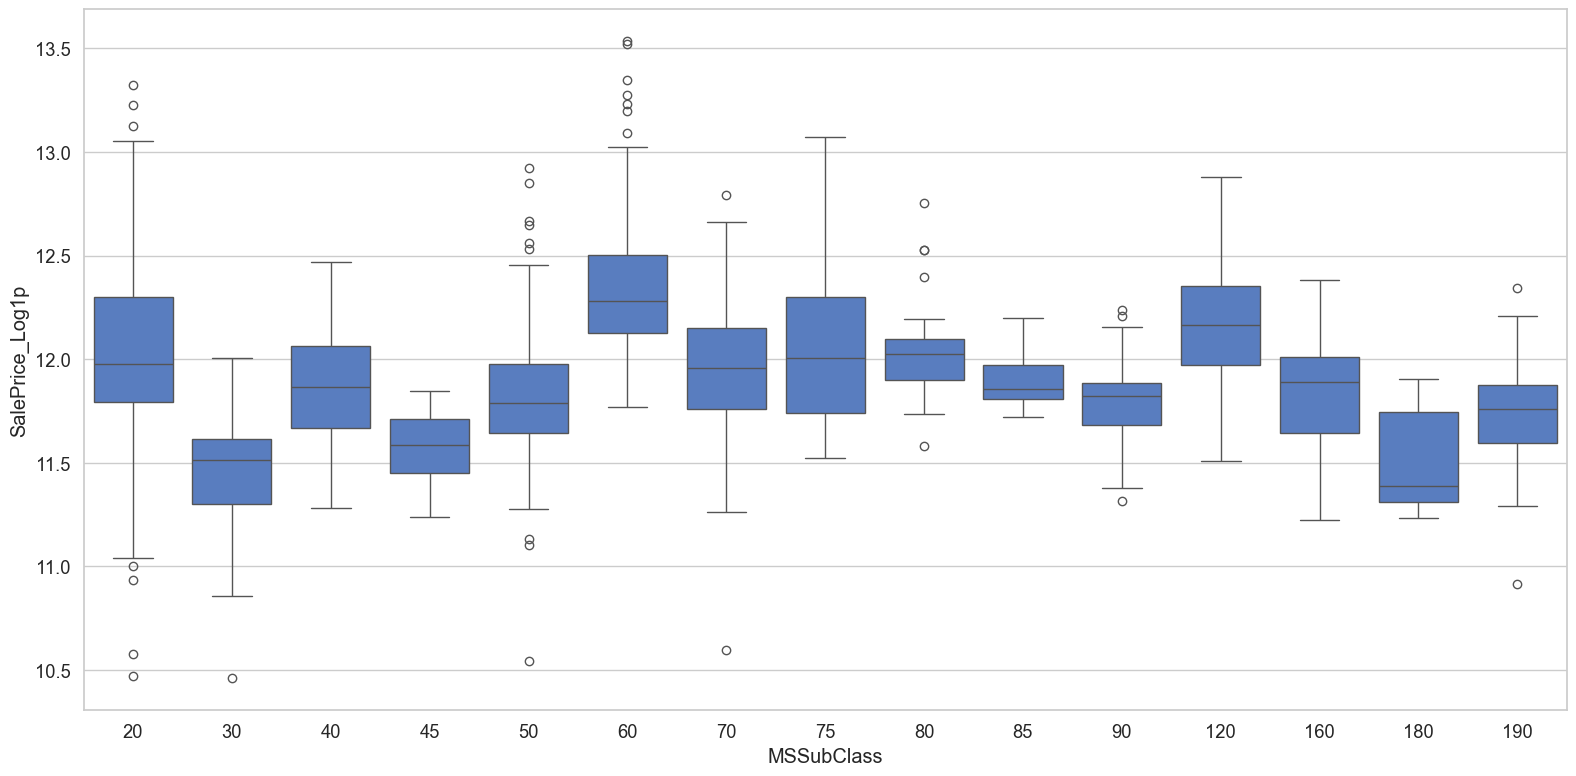

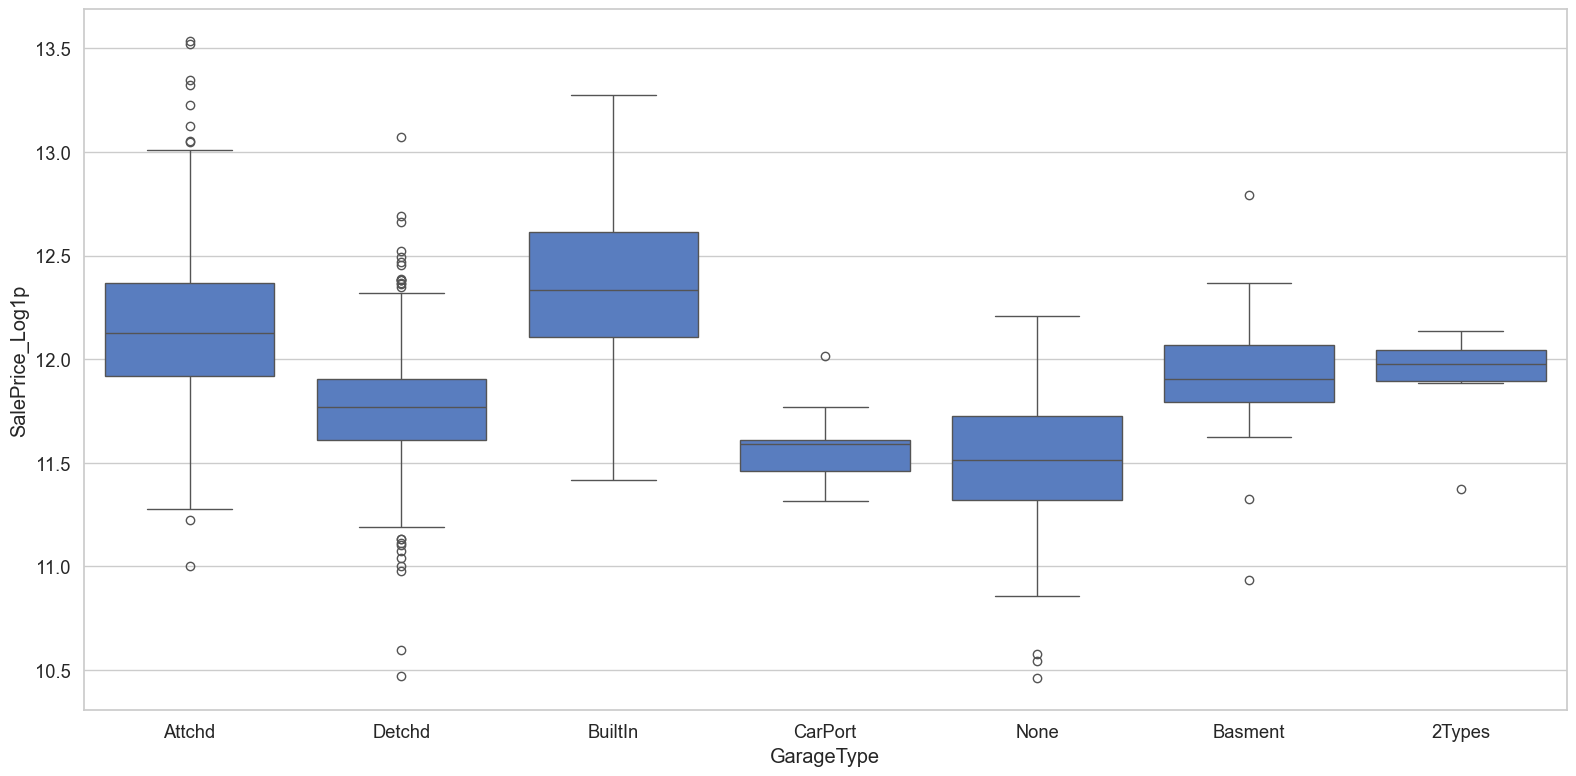

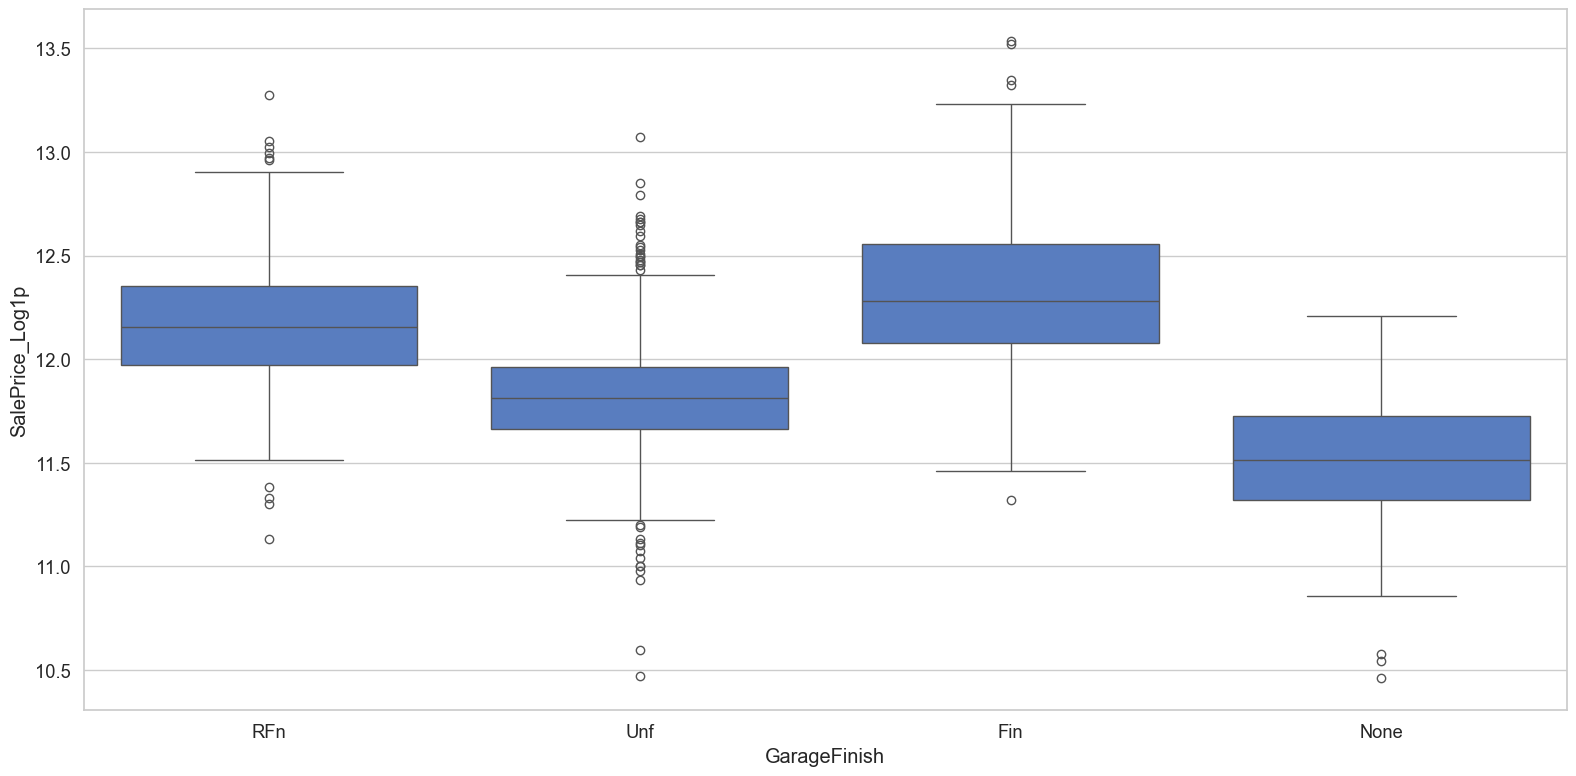

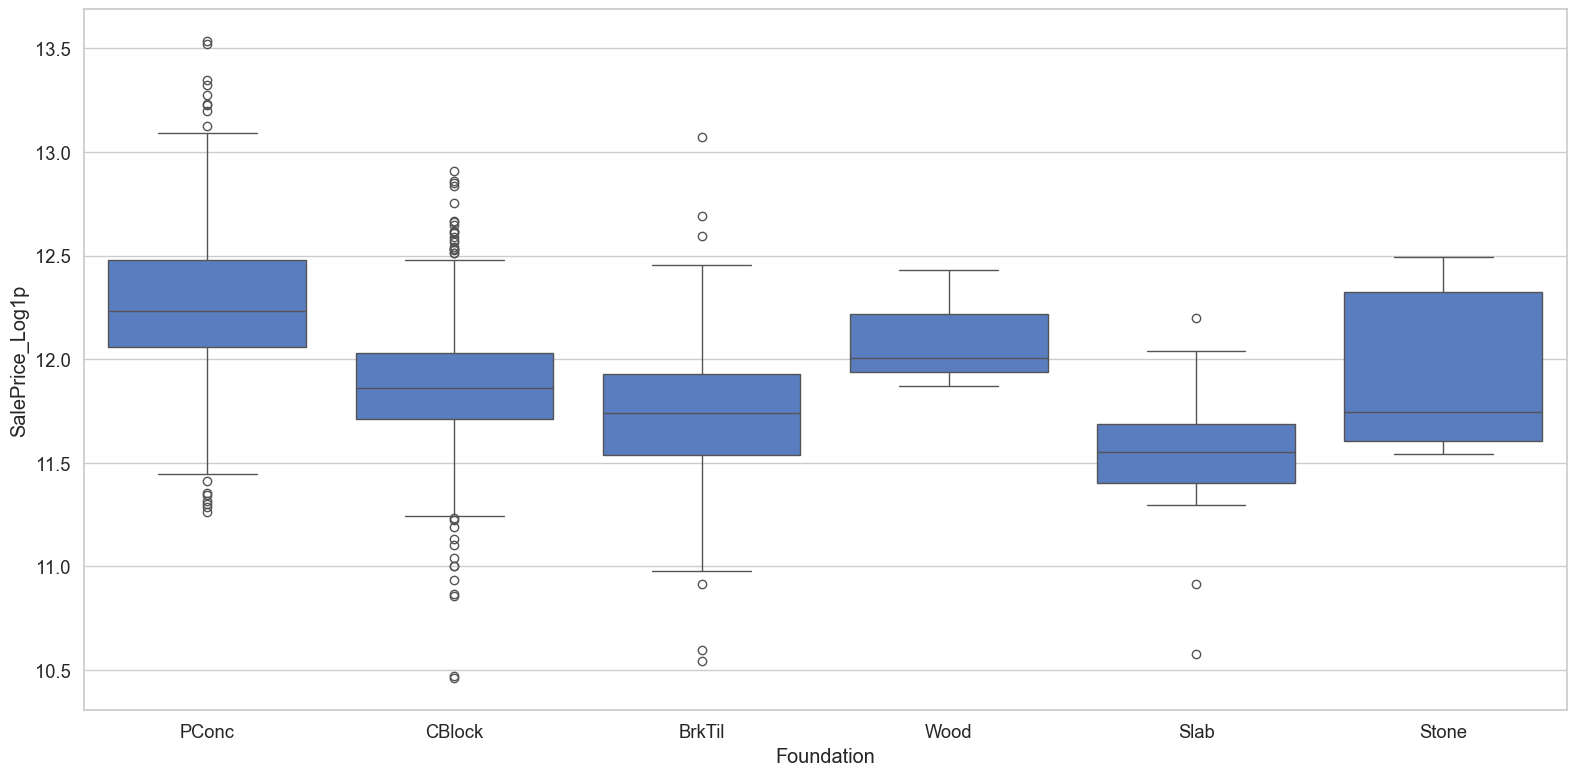

In [22]:
for col in best_cats:
    plt.figure(figsize = (16,8))
    sns.boxplot(x= col, y=target, data = df)
    plt.tight_layout()
    plt.show

In [23]:
focus_num = top_num[:20]
cm = df[focus_num].corr().abs()
high_pairs = [
    (i,j,cm.loc[i,j])
    for i in focus_num for j in focus_num
    if i<j and cm.loc[i,j] > 0.80
]
print('high_multi_lines:', high_pairs)

high_multi_lines: [('GrLivArea', 'TotRmsAbvGrd', np.float64(0.8254893743088424)), ('GarageArea', 'GarageCars', np.float64(0.8824754142814619)), ('1stFlrSF', 'TotalBsmtSF', np.float64(0.8195299750050339))]


## 7. Summary & Insights

- `SalePrice` is right-skewed → log transformation improves normality.  
- Strongest numerical predictors: `OverallQual`, `GrLivArea`, `TotalBsmtSF`.  
- Categorical predictors like `Neighborhood` show large differences in median prices.  
- Several features have high missingness (`PoolQC`, `MiscFeature`), requiring careful preprocessing.  
- Feature engineering (age, total area, bathrooms, etc.) adds domain knowledge.  